# Experiment 9 — Document-type multipliers

Fixed: BM25F, stemming + stopwords, all field boosts = 1, top 100 documents, discounted CombSUM. Only paper/project/course weights vary. Known-positive labels are incomplete.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("bm25_document_weight_results")
if not OUT.exists():
    OUT = Path("testing/bm25_document_weight_results")
summary = pd.read_csv(OUT / "summary.csv")
metrics = pd.read_csv(OUT / "metrics.csv")
rankings = pd.read_csv(OUT / "rankings.csv")
print("Queries:", metrics.query_id.nunique())
print("Configurations:", metrics.configuration.nunique())

Queries: 452
Configurations: 27


## Overall results

In [2]:
overall = summary.query("query_type == 'overall'").sort_values("known_ndcg_at_k", ascending=False)
display(overall[["configuration", "paper_weight", "project_weight", "course_weight", "known_ndcg_at_k", "known_mrr_at_k", "known_recall_at_k"]].round(4))

,configuration,paper_weight,project_weight,course_weight,known_ndcg_at_k,known_mrr_at_k,known_recall_at_k
18,paper1_project3_course1,1.0,3.0,1.0,0.3658,0.3403,0.5056
45,paper2_project3_course1,2.0,3.0,1.0,0.3532,0.3272,0.4865
9,paper1_project2_course1,1.0,2.0,1.0,0.3507,0.3264,0.4818
36,paper2_project2_course1,2.0,2.0,1.0,0.3483,0.3198,0.4845
72,paper3_project3_course1,3.0,3.0,1.0,0.3477,0.3180,0.4849
75,paper3_project3_course2,3.0,3.0,2.0,0.3434,0.3153,0.4812
48,paper2_project3_course2,2.0,3.0,2.0,0.3430,0.3169,0.4783
63,paper3_project2_course1,3.0,2.0,1.0,0.3410,0.3102,0.4844
66,paper3_project2_course2,3.0,2.0,2.0,0.3337,0.3049,0.4730
0,baseline,1.0,1.0,1.0,0.3332,0.3069,0.4683


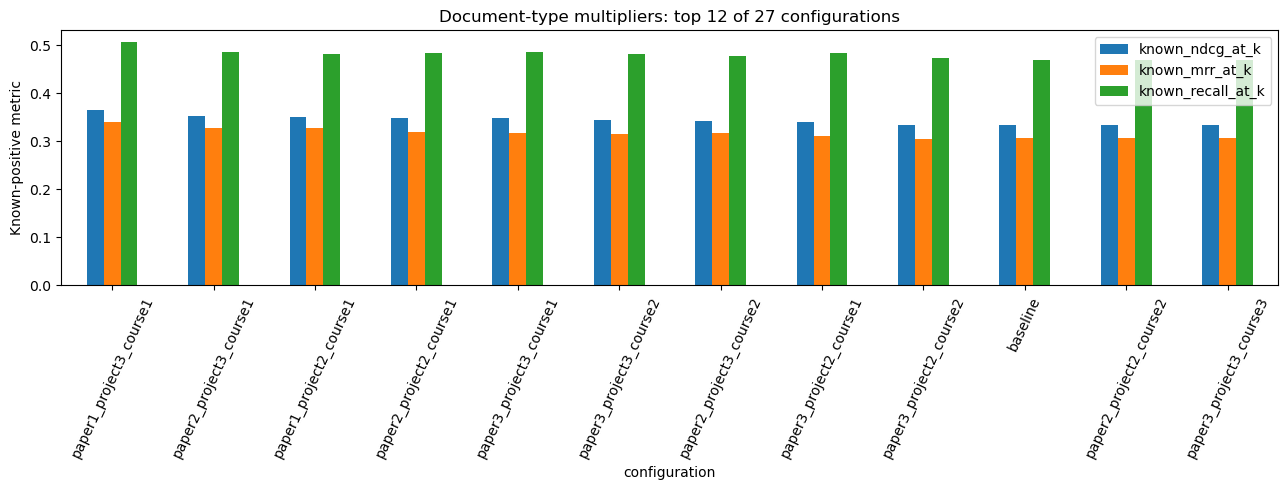

In [3]:
# Show the 12 highest-performing configurations for a readable chart.
top = overall.head(12)
ax = top.plot.bar(x="configuration", y=["known_ndcg_at_k", "known_mrr_at_k", "known_recall_at_k"], figsize=(13,5), rot=65)
ax.set_ylabel("Known-positive metric")
ax.set_title("Document-type multipliers: top 12 of 27 configurations")
plt.tight_layout()
plt.show()


## Academic versus student-style queries

query_type,academic,student_style
configuration,,
paper1_project3_course1,0.4131,0.3185
paper2_project3_course1,0.3998,0.3066
paper1_project2_course1,0.3943,0.3070
paper2_project2_course1,0.3932,0.3033
paper3_project3_course1,0.3921,0.3032
paper3_project3_course2,0.3867,0.3002
paper2_project3_course2,0.3835,0.3025
paper3_project2_course1,0.3845,0.2975
paper3_project2_course2,0.3754,0.2919


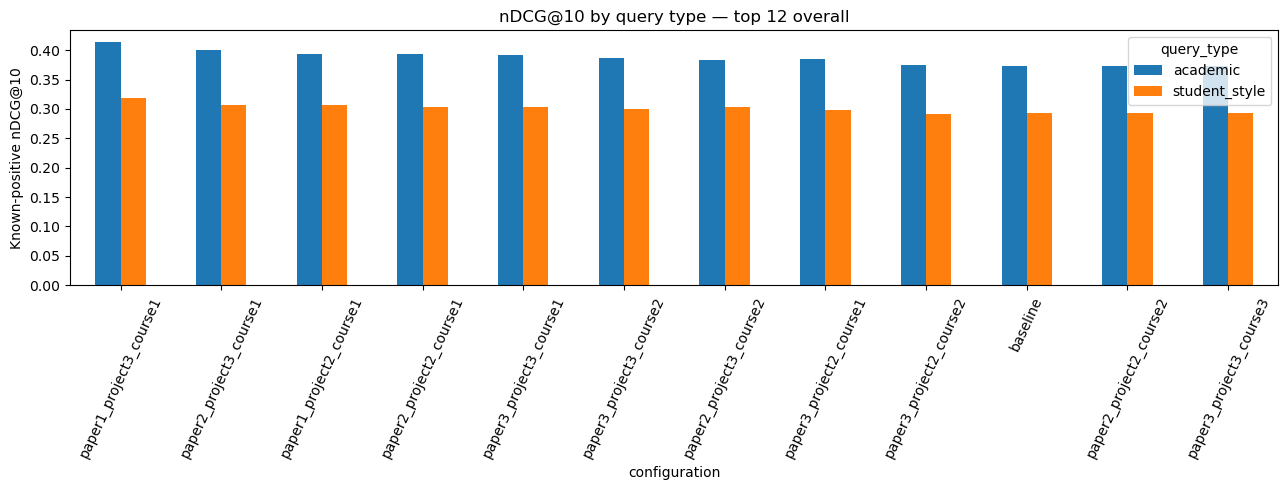

In [4]:
by_type = summary.query("query_type != 'overall'")
pivot = by_type.pivot(index="configuration", columns="query_type", values="known_ndcg_at_k")
display(pivot.loc[overall.configuration].round(4))
pivot.loc[overall.configuration.head(12)].plot.bar(figsize=(13,5), rot=65, title="nDCG@10 by query type — top 12 overall")
plt.ylabel("Known-positive nDCG@10")
plt.tight_layout()
plt.show()


## Paired query differences against baseline

Differences use the *same query IDs*. Confidence intervals are exploratory because queries may share source articles. The weights are exploratory configurations, not tuned on a held-out test set.

In [5]:
wide = metrics.pivot(index="query_id", columns="configuration", values="known_ndcg_at_k")
base = wide["baseline"]
rng = np.random.default_rng(42)
rows=[]
for name in wide.columns:
    if name == "baseline": continue
    delta = (wide[name] - base).dropna().to_numpy()
    boot = np.mean(rng.choice(delta, size=(5000, len(delta)), replace=True), axis=1)
    rows.append({"configuration":name,"mean_delta_ndcg":delta.mean(),"CI_low":np.quantile(boot, .025),"CI_high":np.quantile(boot, .975),"queries":len(delta)})
deltas = pd.DataFrame(rows).sort_values("mean_delta_ndcg", ascending=False)
display(deltas.round(4))

,configuration,mean_delta_ndcg,CI_low,CI_high,queries
5,paper1_project3_course1,0.0326,0.0214,0.0439,452
14,paper2_project3_course1,0.0200,0.0112,0.0289,452
2,paper1_project2_course1,0.0174,0.0104,0.0254,452
11,paper2_project2_course1,0.0150,0.0064,0.0238,452
23,paper3_project3_course1,0.0145,0.0042,0.0248,452
24,paper3_project3_course2,0.0102,0.0034,0.0174,452
15,paper2_project3_course2,0.0098,0.0042,0.0156,452
20,paper3_project2_course1,0.0078,-0.0025,0.0180,452
21,paper3_project2_course2,0.0004,-0.0065,0.0073,452
25,paper3_project3_course3,0.0000,0.0000,0.0000,452


## Top-10 overlap with baseline

A large overlap means weighting mostly reorders the same researchers; a small overlap means it changes which researchers appear.

In [6]:
baseline_sets = rankings.query("configuration == 'baseline'").groupby("query_id").researcher_uuid.apply(set)
rows=[]
for config, group in rankings.groupby("configuration"):
    if config == "baseline": continue
    sets = group.groupby("query_id").researcher_uuid.apply(set)
    overlap = [len(baseline_sets[q] & sets.get(q, set())) for q in baseline_sets.index]
    rows.append({"configuration":config,"mean_top10_overlap":np.mean(overlap),"median_top10_overlap":np.median(overlap)})
display(pd.DataFrame(rows).sort_values("mean_top10_overlap", ascending=False).round(2))

,configuration,mean_top10_overlap,median_top10_overlap
25,paper3_project3_course3,9.98,10.0
12,paper2_project2_course2,9.98,10.0
22,paper3_project2_course3,9.83,10.0
9,paper2_project1_course2,9.72,10.0
15,paper2_project3_course2,9.71,10.0
19,paper3_project1_course3,9.64,10.0
2,paper1_project2_course1,9.45,10.0
24,paper3_project3_course2,9.00,9.0
13,paper2_project2_course3,8.98,9.0
21,paper3_project2_course2,8.94,9.0


### Experiment 9: Document-Type Weighting

A full factorial experiment was conducted to evaluate the influence of document-type weights on expert retrieval effectiveness. Weights of 1, 2, and 3 were independently assigned to papers, projects, and courses, resulting in 27 configurations.

The experiment retained the previously selected preprocessing strategy, retrieval depth of 100, and Discounted CombSUM aggregation.

The best-performing configuration assigned weights of 1 to papers, 3 to projects, and 1 to courses. It achieved an nDCG@10 of 0.3658, MRR@10 of 0.3403, and known-positive Recall@10 of 0.5056, compared with baseline values of 0.3332, 0.3069, and 0.4683, respectively.

The improvement was observed for both academic and student-style queries. Academic nDCG@10 increased from 0.3738 to 0.4131, while student-style nDCG@10 increased from 0.2927 to 0.3185.

Configurations assigning greater relative importance to projects generally outperformed the equal-weight baseline, whereas increasing course weights tended to reduce effectiveness.

These results suggest that project documents provide particularly valuable evidence for expert identification in the evaluated collection. However, the observed advantage may reflect the composition of the corpus and the characteristics of the existing relevance judgments.

Because the best configuration was selected using the same evaluation queries, its performance should be validated on independent relevance judgments before drawing strong conclusions about generalization.